In [6]:
import pandas as pd
df= pd.read_csv('sales_data.csv', encoding='unicode_escape')

In [7]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [9]:
df.nunique()

ORDERNUMBER          307
QUANTITYORDERED       58
PRICEEACH           1016
ORDERLINENUMBER       18
SALES               2763
ORDERDATE            252
STATUS                 6
QTR_ID                 4
MONTH_ID              12
YEAR_ID                3
PRODUCTLINE            7
MSRP                  80
PRODUCTCODE          109
CUSTOMERNAME          92
PHONE                 91
ADDRESSLINE1          92
ADDRESSLINE2           9
CITY                  73
STATE                 16
POSTALCODE            73
COUNTRY               19
TERRITORY              3
CONTACTLASTNAME       77
CONTACTFIRSTNAME      72
DEALSIZE               3
dtype: int64

In [10]:
df.isna().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [11]:
df= df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

In [12]:
df.head()

,QUANTITYORDERED,PRICEEACH,SALES
0,30,95.70,2871.00
1,34,81.35,2765.90
2,41,94.74,3884.34
3,45,83.26,3746.70
4,49,100.00,5205.27


In [14]:
df.nunique()

QUANTITYORDERED      58
PRICEEACH          1016
SALES              2763
dtype: int64

In [15]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_scaled= scaler.fit_transform(df)

In [16]:
inertia=[]
K=range(1,20)
from sklearn.cluster import KMeans
for k in K:
    model= KMeans(n_clusters= k, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

Text(0.5, 1.0, 'Elbow graph')

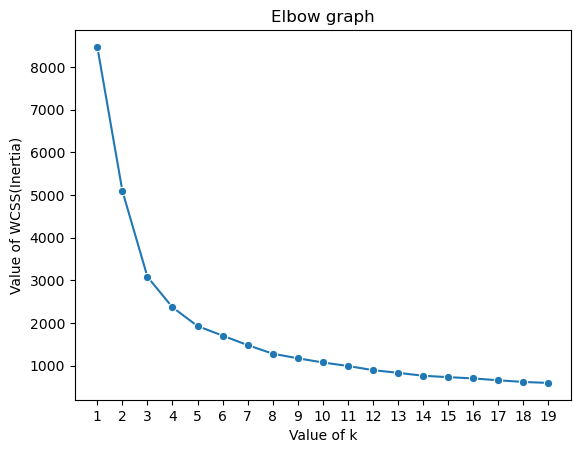

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.lineplot(x=K, y=inertia, marker='o')
plt.xticks(K)
plt.xlabel("Value of k")
plt.ylabel("Value of WCSS(Inertia)")
plt.title("Elbow graph")


In [34]:
optimal_k=4
model2= KMeans(n_clusters= optimal_k, random_state=42)
model2.fit(X_scaled)
df['class']= model2.predict(X_scaled)
model2.cluster_centers_


array([[ 0.88837014, -0.9081365 , -0.38422378],
       [ 0.89862134,  0.76500597,  1.29856015],
       [-0.72804963, -1.31000158, -1.07006862],
       [-0.7480042 ,  0.63653603, -0.17974302]])

In [27]:
df['class']

0       3
1       3
2       1
3       0
4       1
       ..
2818    3
2819    3
2820    1
2821    2
2822    0
Name: class, Length: 2823, dtype: int32

Text(0.5, 1.0, 'k means clustering with k=4')

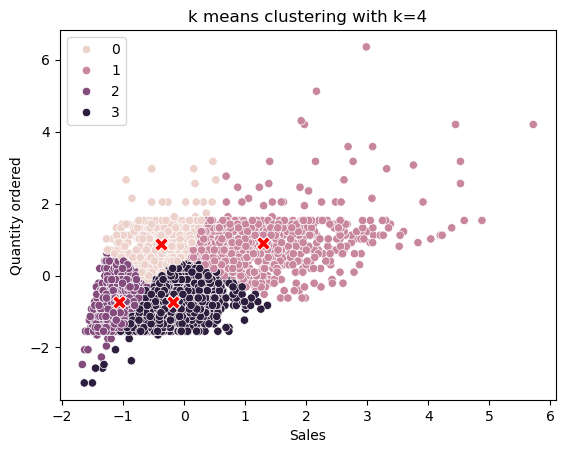

In [46]:

sns.scatterplot(x=X_scaled[:,2], y=X_scaled[:,0], hue=df['class'])
sns.scatterplot(x=model2.cluster_centers_[:,2],y=model2.cluster_centers_[:,0], marker='X', s=100, color='red')
plt.xlabel("Sales")
plt.ylabel("Quantity ordered")
plt.title("k means clustering with k=4")